# **Stock Sentiment**

Predicting market behavior from tweets


---






#### Group 23
2024/2025



---


#### This project was done by:

Student Name - Ana Pedro Martins Caleiro <br>
Student id - 20240696 <br>
Contact e-mail - 20240696@novaims.unl.pt <br>

Student Name -  André Alexandre Loureiro Lourenço<br>
Student id -   20240743 <br>
Contact e-mail - 20240743@novaims.unl.pt <br>

Student Name -  Duarte Manuel Figueirinha Marques <br>
Student id -   20240522 <br>
Contact e-mail - 20240522@novaims.unl.pt <br>

Student Name -  Érica Yeranosyan Parracho  <br>
Student id - 20240583 <br>
Contact e-mail - 20240583@novaims.unl.pt  <br>

Student Name - Jude Gbenimako   <br>
Student id -  20240700 <br>
Contact e-mail - 20240700@novaims.unl.pt <br>



# **Table of Contents**


>[0. Context and Metadata](#scrollTo=_ixChZdpvz9d)

>[1. Importing Libraries and Loading Data](#scrollTo=fbnMMfpowBga)

>>[1.1. Importing Libraries](#scrollTo=lmO9O3HWwKc8)

>>[1.2. Functions](#scrollTo=3xtXXG-4-5b5)

>>[1.3. Loading and Reading the Data](#scrollTo=t3CZSJZNw928)

>>[1.4. Brief Preliminary Analysis](#scrollTo=61OqC5mj0sS6)

>>>>[1.4.1. Test Data](#scrollTo=RKV7i8gP7rX5)

>>>>[1.4.2. Train Data](#scrollTo=OLVpRvi-7vtJ)

>[2. Exploratory Data Analysis (EDA)](#scrollTo=0d00_7Ii6jNC)

>>[2.1. Dristibution of labels](#scrollTo=WvdlbOc39dh0)

>>[2.2. Creation of features](#scrollTo=5bePCAZIBSrp)

>>[2.3. Hastags and Mentions](#scrollTo=p9OqZY94AS0z)

>>>[2.3.1. Frequency](#scrollTo=JcqCk8n_BDiR)

>>>[2.3.2. Hashtags](#scrollTo=N5sFkX_PDQUr)

>>>[2.3.3. Mentions](#scrollTo=27TpRjwSDS1s)

>>[2.4. Text Distribution](#scrollTo=9WW3ODlcMmWW)

>>>[2.4.1. Distribution of Text Lengths](#scrollTo=af-w565UNUIy)

>>>[2.4.2. Distribution of Unique words](#scrollTo=53_mT21CNbnX)

>>>[2.4.3. Distribution of Stopwords](#scrollTo=tFcabBBZNe_W)

>>>[2.4.4. Understanding whether these distributions differ depending on the sentiment.](#scrollTo=gTO_gxBlN2hV)

>>[2.5. Multivariate Analysis](#scrollTo=vn5WqVHpRJQv)

>>>[2.5.1. Scatter Plot Analysis](#scrollTo=g9o6HUlQTCIE)

>>>[2.5.2. Boxplot Analysis](#scrollTo=49xr8VmbUXkZ)

>>>[2.5.3. Correlation Matrix](#scrollTo=ET-7fdW_OsQk)

>>[2.6. Word Analysis](#scrollTo=jdiPnE8RQUlm)

>>>[2.6.1. Word Frequency](#scrollTo=Z_vlGNGhQW8j)

>>>[2.6.2. Raw Text Wordcloud](#scrollTo=6ASJig0YQdu7)

>>>[2.6.3. Wordcloud by Sentiment](#scrollTo=H6odRGcfQnxY)



# **0. Context and Metadata**

We are performing a sentiment analysis of the stock market, predicting its behavior based on tweets. To accomplish this, we will use a classification model and NLP techniques to speculate the sentiment of each tweet (Bearish (0), Bullish (1), or Neutral (2)).

**Purpose of the notebook:**

In this notebook, we are conducting exploratory data analysis (EDA). The main goal is to gain insights through visualizations and better understand the context of the data.






# **1. Importing Libraries and Loading Data**




## **1.1. Importing Libraries**






In [ ]:
#!pip install contractions
#!pip install pyspellchecker

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import string
import re
import nltk
import contractions
from spellchecker import SpellChecker

from tqdm import trange
from tqdm import tqdm
from nltk import tokenize
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

## **1.2. Functions**

EDA Fucntions

In [ ]:
# collecting the hashtags
def hashtag_extract(x):
    hashtags = []

    for i in x:
        ht = re.findall(r"#(\w+)", i)
        hashtags.append(ht)

    return hashtags

In [ ]:
# Collecting the mentions
def mention_extract(x):
    mentions = []

    for i in x:
        mt = re.findall(r"@(\w+)", i)
        mentions.append(mt)

    return mentions


In [ ]:
# Couting the number of words
def number_words(tweet_text):
    text_list = tweet_text.split()
    return(len(text_list))

## **1.3. Loading and Reading the Data**

In [ ]:
train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')
pd.set_option("display.max_columns", None)

In [ ]:
print(train_data.head(5))
print(train_data.tail(5))

                                                text  label
0  $BYND - JPMorgan reels in expectations on Beyo...      0
1  $CCL $RCL - Nomura points to bookings weakness...      0
2  $CX - Cemex cut at Credit Suisse, J.P. Morgan ...      0
3  $ESS: BTIG Research cuts to Neutral https://t....      0
4  $FNKO - Funko slides after Piper Jaffray PT cu...      0
                                                   text  label
9538  The Week's Gainers and Losers on the Stoxx Eur...      2
9539  Tupperware Brands among consumer gainers; Unil...      2
9540  vTv Therapeutics leads healthcare gainers; Myo...      2
9541    WORK, XPO, PYX and AMKR among after hour movers      2
9542             YNDX, I, QD and OESX among tech movers      2


In [ ]:
print(test_data.head(5))
print(test_data.tail(5))

   id                                               text
0   0  ETF assets to surge tenfold in 10 years to $50...
1   1  Here’s What Hedge Funds Think Evolution Petrol...
2   2  $PVH - Phillips-Van Heusen Q3 2020 Earnings Pr...
3   3  China is in the process of waiving retaliatory...
4   4  Highlight: “When growth is scarce, investors s...
        id                                               text
2383  2383  $IVC - Invacare Corporation (IVC) CEO Matthew ...
2384  2384       Domtar EPS misses by $0.05,  revenue in-line
2385  2385  India Plans Incentives to Bring In Foreign Man...
2386  2386  $NVCR shows institutional accumulation with bl...
2387  2387  accesso Technology : Form 8.3 - Accesso Techno...


## **1.4. Brief Preliminary Analysis**

#### 1.4.1. Test Data

In [ ]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2388 entries, 0 to 2387
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2388 non-null   int64 
 1   text    2388 non-null   object
dtypes: int64(1), object(1)
memory usage: 37.4+ KB


#### 1.4.2. Train Data

In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9543 entries, 0 to 9542
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    9543 non-null   object
 1   label   9543 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 149.2+ KB


In [ ]:
train_data["label"].value_counts(normalize=True)

,proportion
label,
2,0.647386
1,0.201509
0,0.151106


In [ ]:
train_data["label"].describe()

,label
count,9543.000000
mean,1.496280
std,0.743139
min,0.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,2.000000


In [ ]:
train_data["label"].isna().sum()

np.int64(0)

**Notes**


*  Our labels are imbalanced, with label 2 being the most frequent one.
* No missing Values



# **2. Exploratory Data Analysis (EDA)**

## 2.1. Dristibution of labels

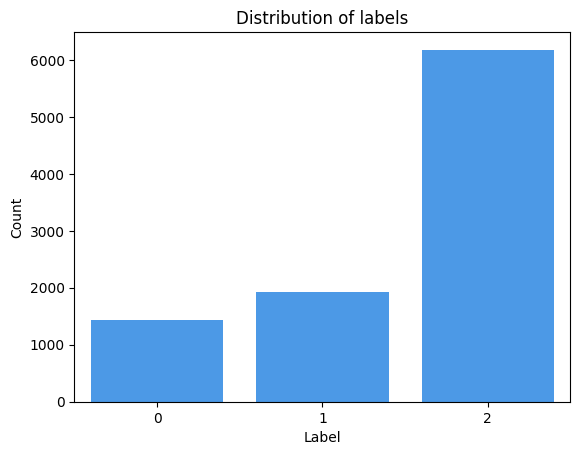

In [ ]:
sns.countplot(data=train_data, x='label', color='#3399FF')
plt.title("Distribution of labels")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

## 2.2. Creation of features

**Note**: We are creating this features before spliting our data since they are performed in raw text. They do not require fitting and will likely not be used in the modeling process, but rather to assist with data interpretation.

In [ ]:
train_data['length'] = train_data["text"].str.len()
train_data['word_count'] = train_data['text'].apply(number_words)

In [ ]:
train_data['mean_word_length'] = train_data['length']/train_data["word_count"]
train_data["num_upper_words"] = train_data['text'].apply(all_upper)
train_data['num_sentences'] = train_data["text"].apply(count_sentence)
train_data['num_unique_words'] = train_data['text'].apply(count_unique_words)
train_data['num_hastags'] = train_data["text"].apply(count_htags)
train_data['num_mentions'] = train_data["text"].apply(count_mentions)
train_data['num_$_as_index'] = train_data["text"].apply(count_index)
train_data['num_$_money'] = train_data["text"].apply(count_value)
train_data['num_stopwords'] = train_data['text'].apply(count_stopwords)

In [ ]:
train_data['unique_words_ratio'] = train_data["num_unique_words"]/train_data["word_count"]
train_data['stopword_ratio'] = train_data['num_stopwords']/train_data['word_count']

In [ ]:
# Verifying if the all the new features were correctly added
train_data.head(3)

,text,label,length,word_count,mean_word_length,num_upper_words,num_sentences,num_unique_words,num_hastags,num_mentions,num_$_as_index,num_$_money,num_stopwords,unique_words_ratio,stopword_ratio
0,$BYND - JPMorgan reels in expectations on Beyo...,0,77,10,7.700000,1,1,10,0,0,1,0,2,1.0,0.200000
1,$CCL $RCL - Nomura points to bookings weakness...,0,102,14,7.285714,2,1,14,0,0,2,0,3,1.0,0.214286
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",0,94,14,6.714286,2,1,14,0,0,1,0,2,1.0,0.142857


## 2.3. Hastags and Mentions

### 2.3.1. Frequency

In [ ]:
print(train_data["num_hastags"].value_counts())
print(train_data["num_mentions"].value_counts())

num_hastags
0    8647
3     497
2     259
1     132
5       6
7       1
4       1
Name: count, dtype: int64
num_mentions
0    9250
1     255
2      34
6       2
8       1
3       1
Name: count, dtype: int64


### 2.3.2. Hashtags

In [ ]:
# extracting hashtags from Bearish attitude
HT_negative = hashtag_extract(train_data['text'][train_data['label'] == 0])

# extracting hashtags from Bullish attitude
HT_positive = hashtag_extract(train_data['text'][train_data['label'] == 1])

# extracting hashtags from Neutral attitude
HT_neutral = hashtag_extract(train_data['text'][train_data['label'] == 2])

# unnesting list
HT_negative = sum(HT_negative,[])
HT_positive = sum(HT_positive,[])
HT_neutral = sum(HT_neutral,[])


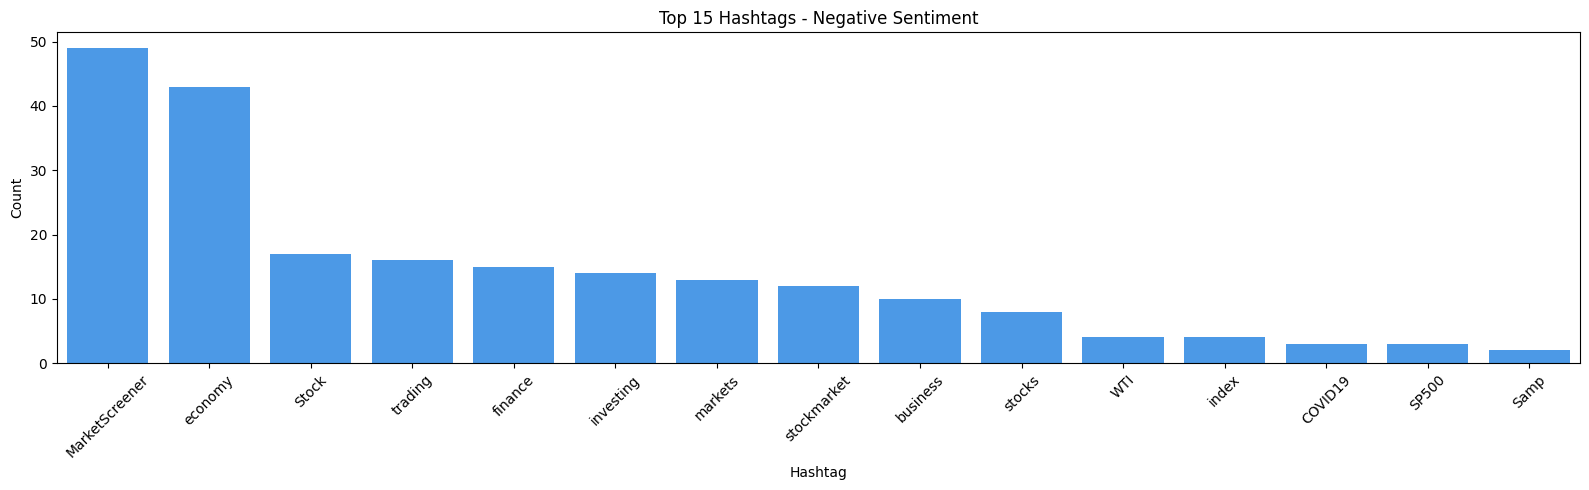

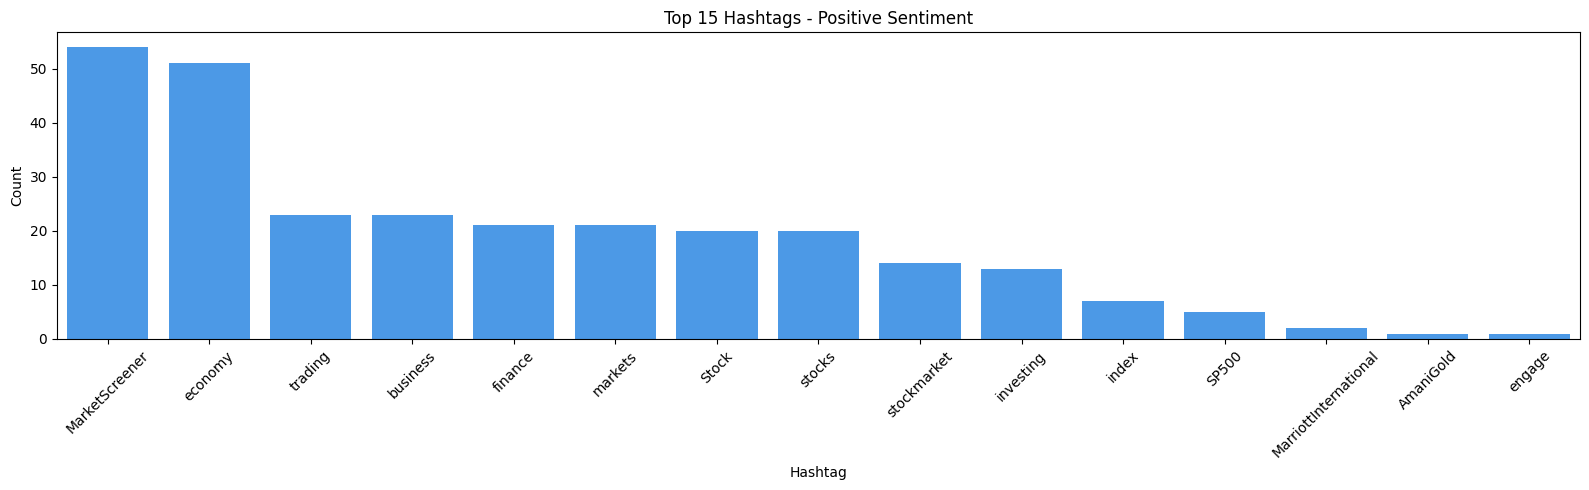

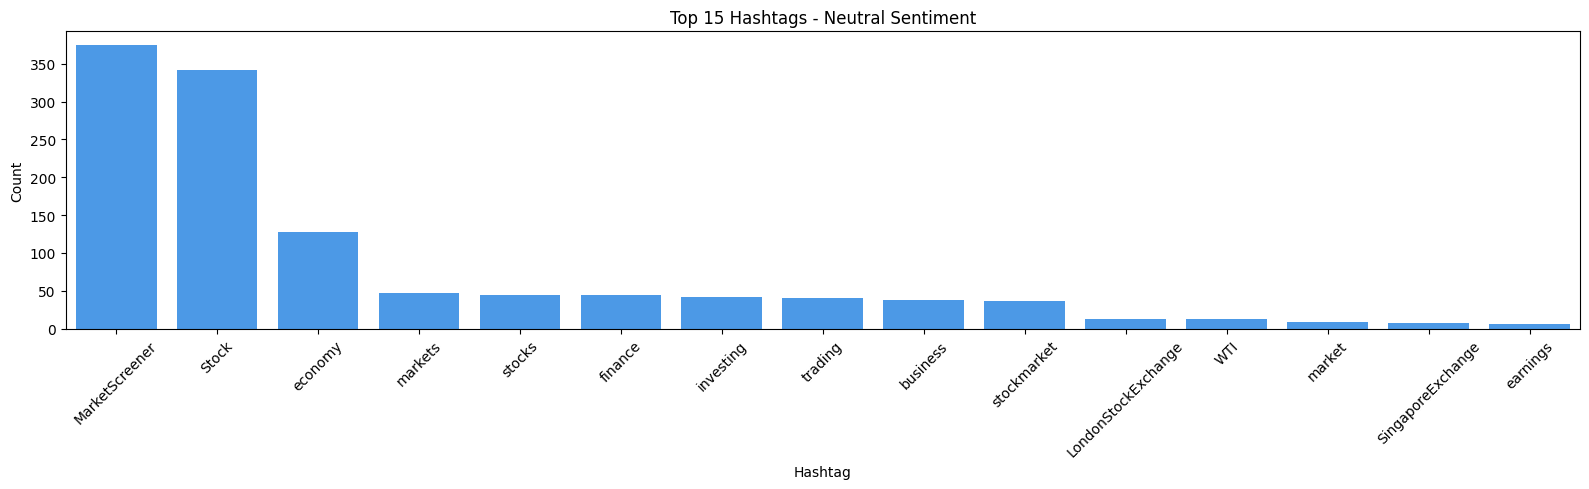

In [ ]:
hashtag_lists = {
    'Negative': HT_negative,
    'Positive': HT_positive,
    'Neutral': HT_neutral
}

# Looping through each label(sentiment)
for sentiment, hashtag_list in hashtag_lists.items():
    freq_dist = nltk.FreqDist(hashtag_list)

    df = pd.DataFrame({
        'Hashtag': list(freq_dist.keys()),
        'Count': list(freq_dist.values())
    })

    # Selecting top 15 hashtags
    top_df = df.nlargest(columns="Count", n=15)

    # Plot
    plt.figure(figsize=(16, 5))
    ax = sns.barplot(data=top_df, x="Hashtag", y="Count", color='#3399FF')
    ax.set(title=f"Top 15 Hashtags - {sentiment} Sentiment", ylabel='Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


### 2.3.3. Mentions

In [ ]:
# extracting hashtags from Bearish attitude
MT_negative = mention_extract(train_data['text'][train_data['label'] == 0])

# extracting hashtags from Bullish attitude
MT_positive = mention_extract(train_data['text'][train_data['label'] == 1])

# extracting hashtags from Neutral attitude
MT_neutral = mention_extract(train_data['text'][train_data['label'] == 2])

# unnesting list
MT_negative = sum(MT_negative,[])
MT_positive = sum(MT_positive,[])
MT_neutral = sum(MT_neutral,[])


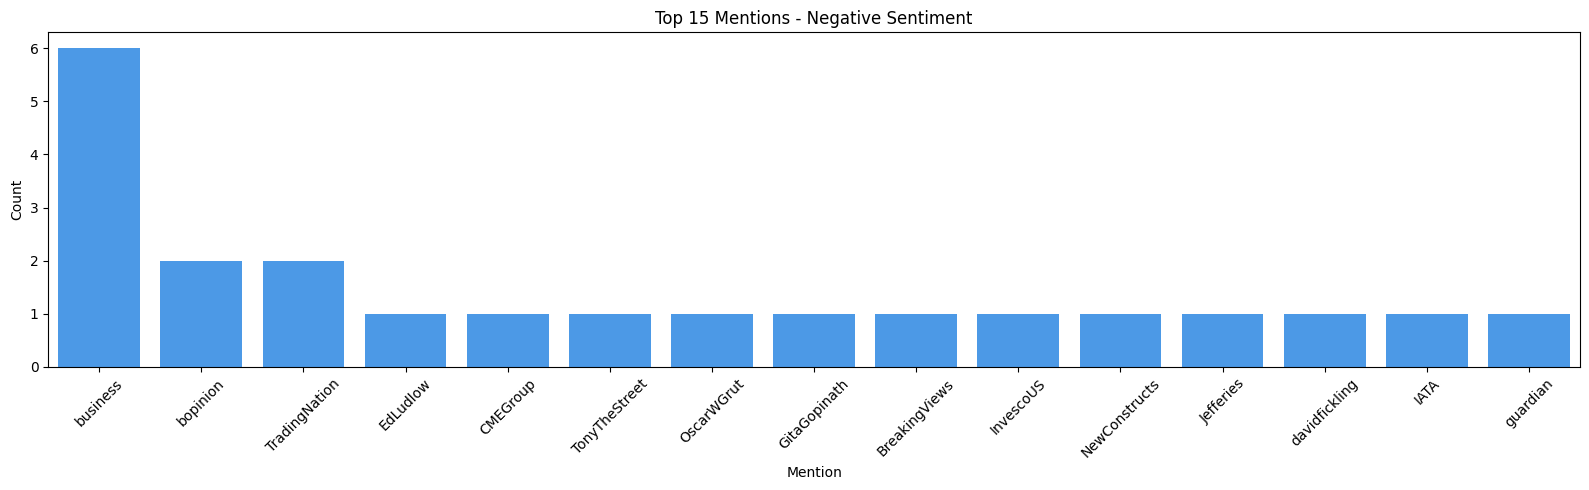

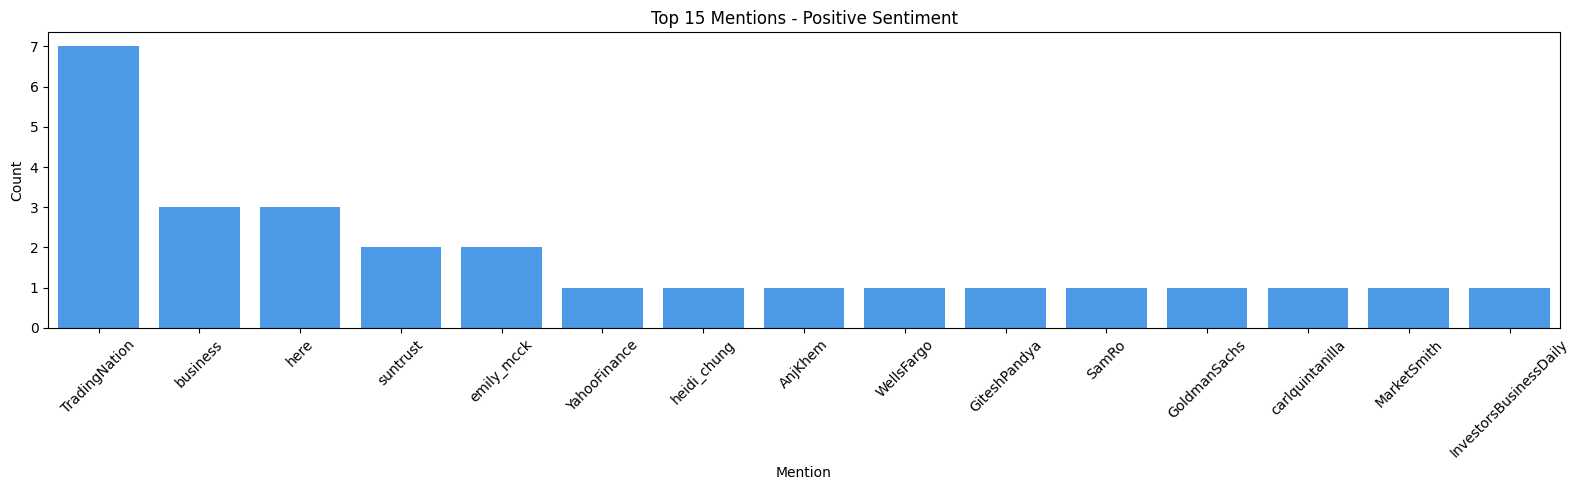

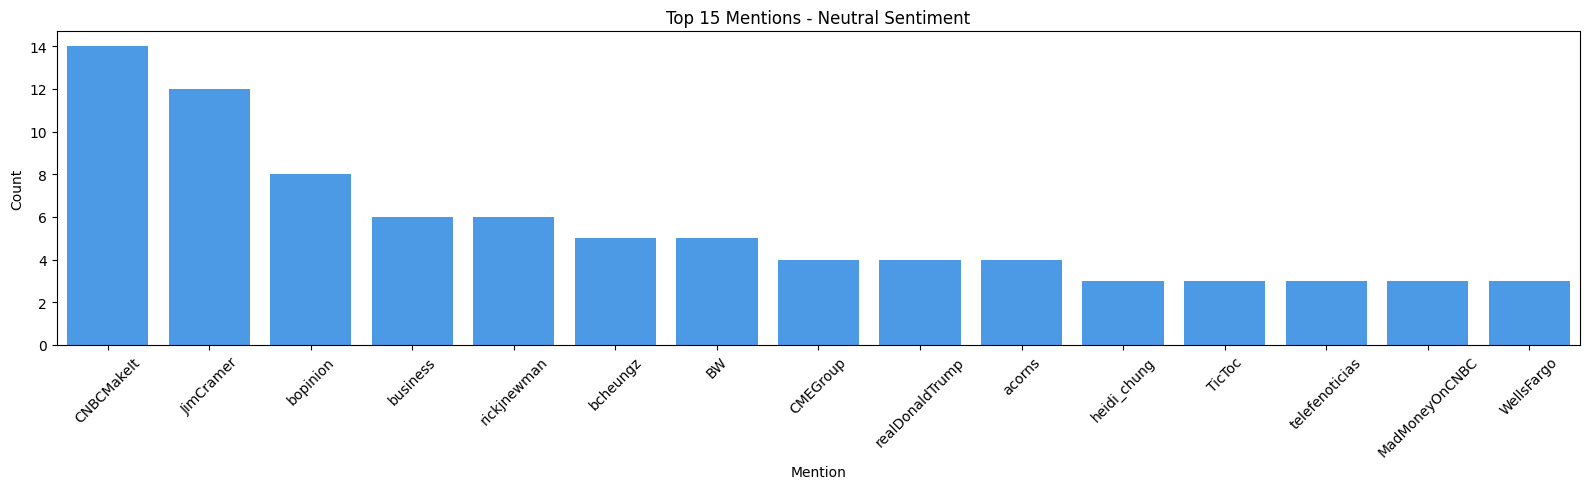

In [ ]:
mention_lists = {
    'Negative': MT_negative,
    'Positive': MT_positive,
    'Neutral': MT_neutral
}

# Looping through each label (sentiment)
for sentiment, mention_list in mention_lists.items():
    freq_dist = nltk.FreqDist(mention_list)

    df = pd.DataFrame({
        'Mention': list(freq_dist.keys()),
        'Count': list(freq_dist.values())
    })

    # Selecting top 15 mentions
    top_df = df.nlargest(columns="Count", n=15)

    # Plot
    plt.figure(figsize=(16, 5))
    ax = sns.barplot(data=top_df, x="Mention", y="Count", color='#3399FF')
    ax.set(title=f"Top 15 Mentions - {sentiment} Sentiment", ylabel='Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


**Observations**

It’s interesting to observe that the hashtags remain kinda similar across different market sentiments, but mentions tend to vary. Neutral tweets often reference general business adive or news, while positive and negative tweets mention more trading-focused accounts like TradingNations and Yahoo Finance. This suggests that when sentiment is negative and, specially, positive, people may seek more specific investment-related information, meaning they are more open to invest.

## 2.4. Text Distribution

### 2.4.1. Distribution of Text Lengths

In [ ]:
train_data['word_count'] = train_data['text'].apply(number_words)

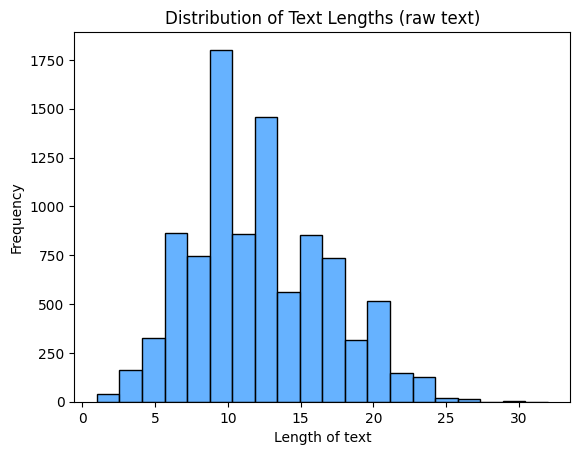

In [ ]:
sns.histplot(train_data['word_count'], bins=20, color='#3399FF')
plt.title("Distribution of Text Lengths (raw text)")
plt.xlabel("Length of text")
plt.ylabel("Frequency")
plt.show()

### 2.4.2. Distribution of Unique words

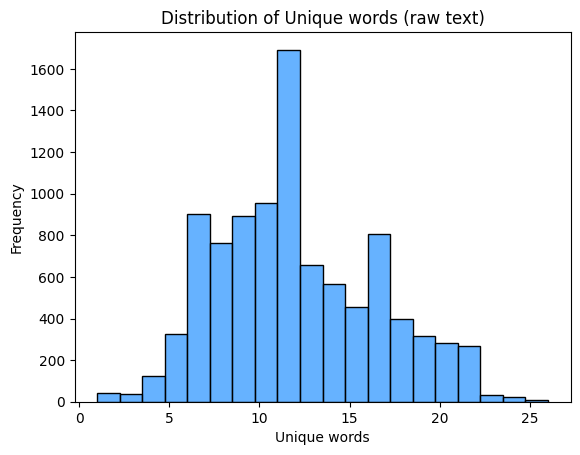

In [ ]:
sns.histplot(train_data['num_unique_words'], bins=20, color='#3399FF')
plt.title("Distribution of Unique words (raw text)")
plt.xlabel("Unique words")
plt.ylabel("Frequency")
plt.show()

### 2.4.3. Distribution of Stopwords

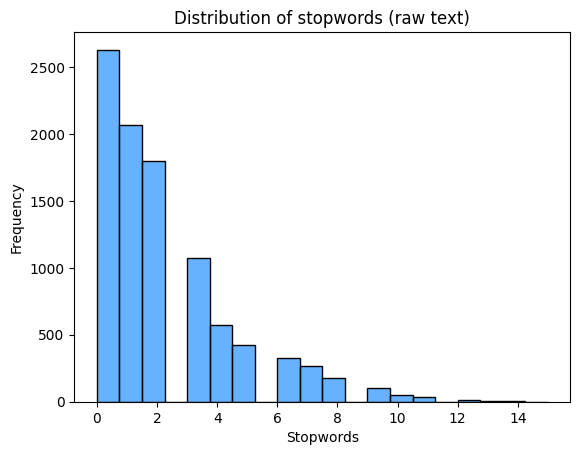

In [ ]:
sns.histplot(train_data['num_stopwords'], bins=20, color='#3399FF')
plt.title("Distribution of stopwords (raw text)")
plt.xlabel("Stopwords")
plt.ylabel("Frequency")
plt.show()

### 2.4.4. Understanding whether these distributions differ depending on the sentiment.

In [ ]:
blue_palette = ["#A3D5FF", "#3399FF", "#003366"]

Text Lengths

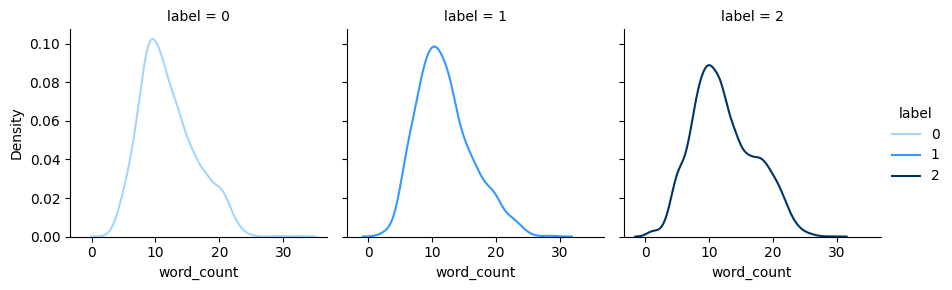

In [ ]:
g = sns.FacetGrid(train_data, col='label', hue='label', col_wrap=3, sharey=True, palette=blue_palette)
g.map_dataframe(sns.kdeplot, x='word_count')
g.add_legend()

plt.show()

Number of Unique Words

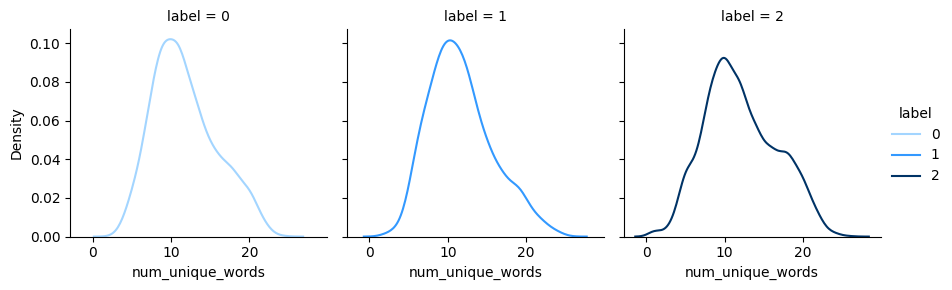

In [ ]:
g = sns.FacetGrid(train_data, col='label', hue='label', col_wrap=3, sharey=True, palette=blue_palette)
g.map_dataframe(sns.kdeplot, x='num_unique_words')
g.add_legend()

plt.show()

Ratio of Unique Words

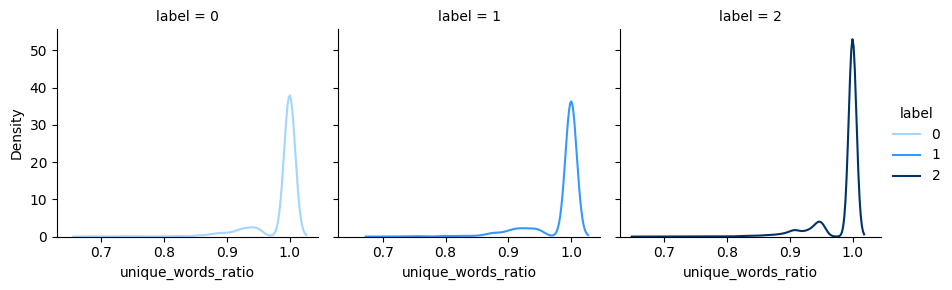

In [ ]:
g = sns.FacetGrid(train_data, col='label', hue='label', col_wrap=3, sharey=True,palette=blue_palette)
g.map_dataframe(sns.kdeplot, x='unique_words_ratio')
g.add_legend()

plt.show()

Number of Stopwords

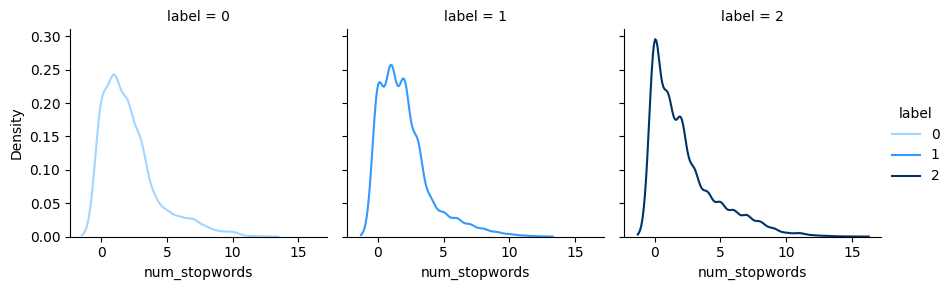

In [ ]:
g = sns.FacetGrid(train_data, col='label', hue='label', col_wrap=3, sharey=True, palette=blue_palette)
g.map_dataframe(sns.kdeplot, x='num_stopwords')
g.add_legend()

plt.show()

Ratio of Stopwords

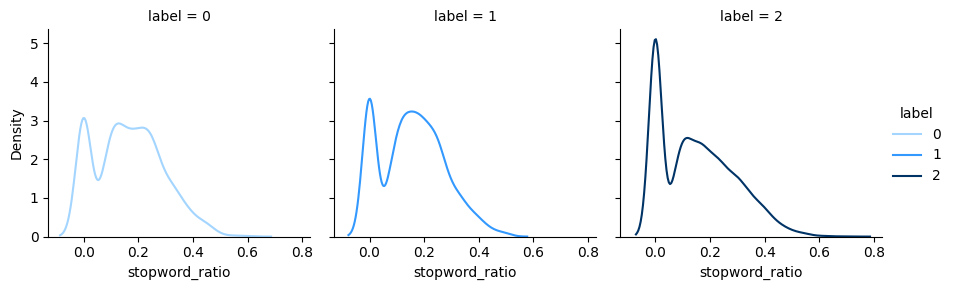

In [ ]:
g = sns.FacetGrid(train_data, col='label', hue='label', col_wrap=3, sharey=True, palette=blue_palette)
g.map_dataframe(sns.kdeplot, x='stopword_ratio')
g.add_legend()

plt.show()

## 2.5. Multivariate Analysis

In [ ]:
feature = train_data[['word_count', 'mean_word_length',
       'num_upper_words', 'num_sentences', 'num_unique_words', 'num_hastags',
       'num_mentions', 'num_$_as_index', 'num_$_money', 'num_stopwords',
       'unique_words_ratio', 'stopword_ratio']]

### 2.5.1. Scatter Plot Analysis

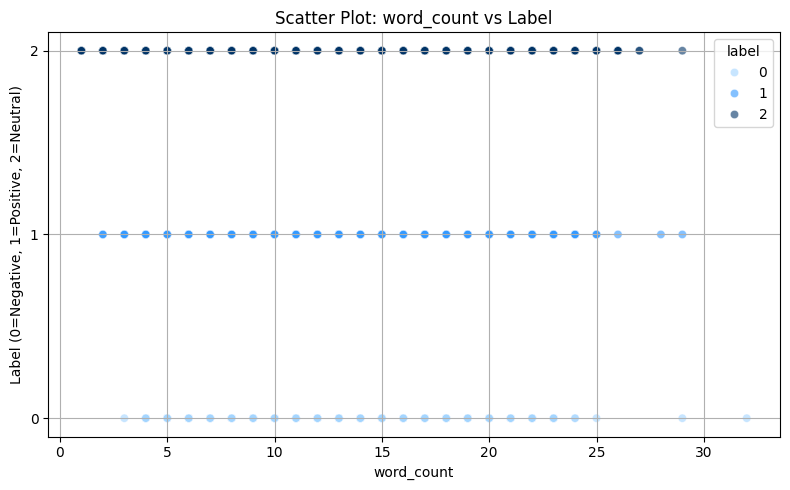

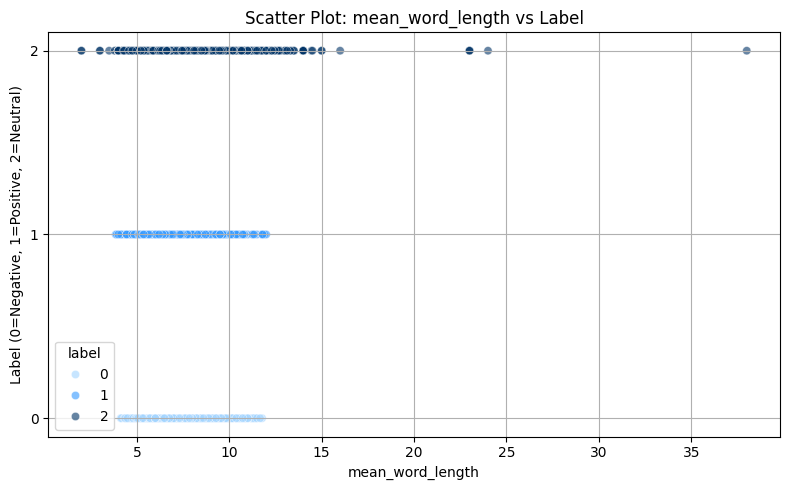

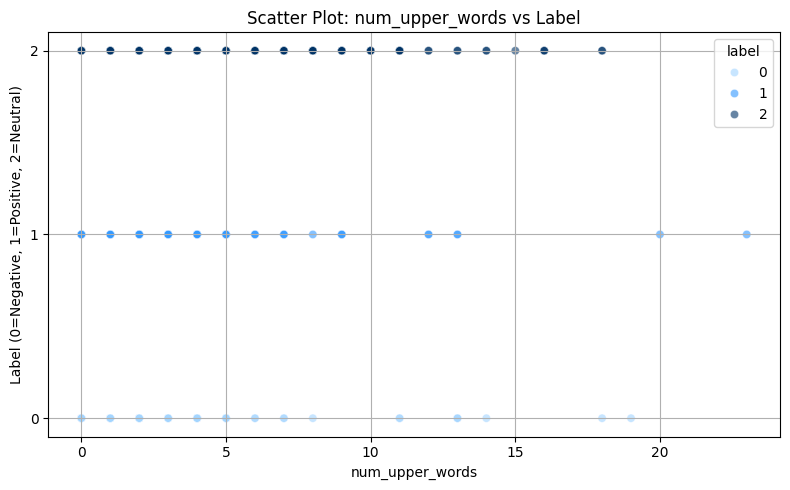

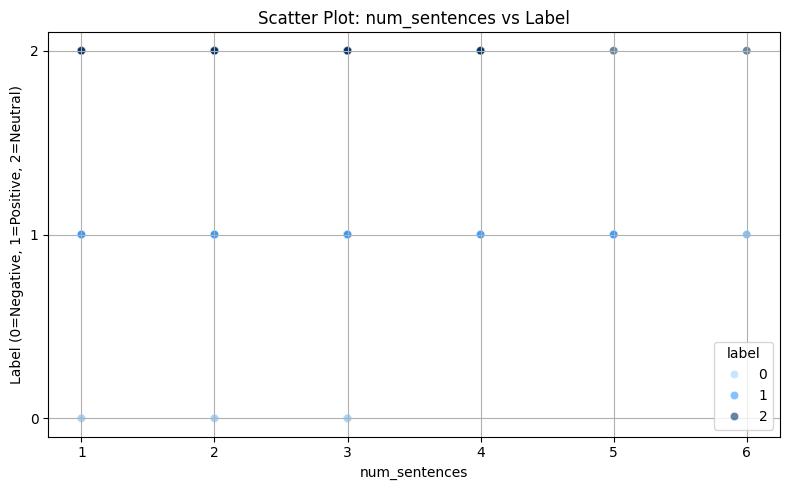

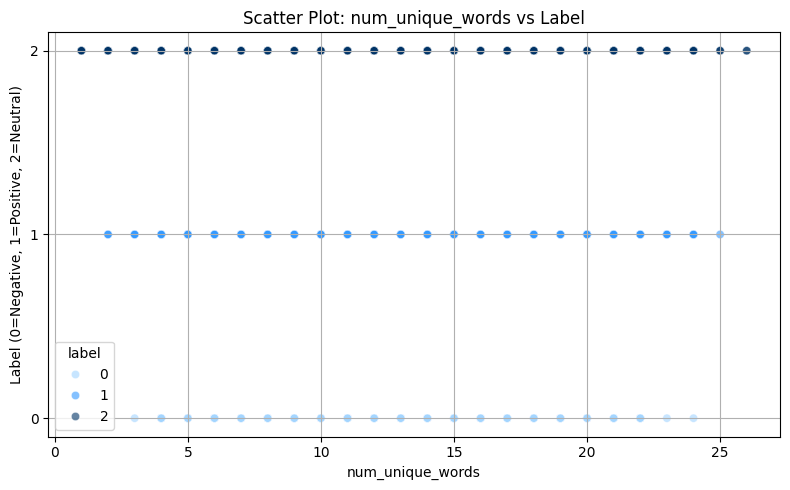

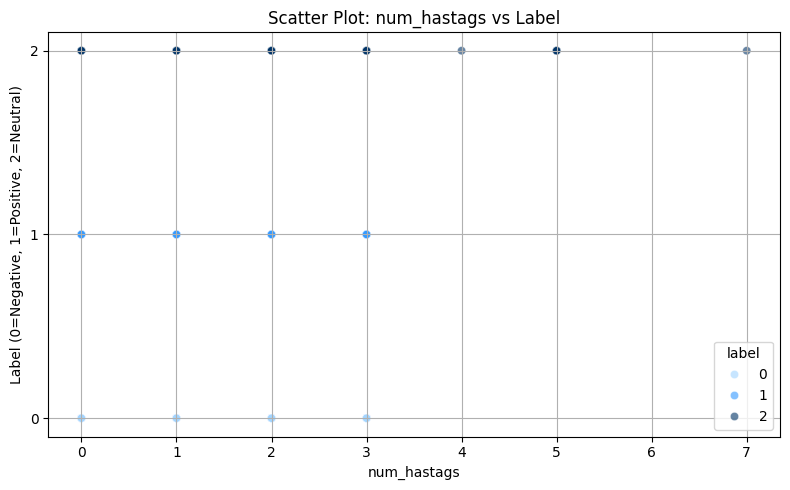

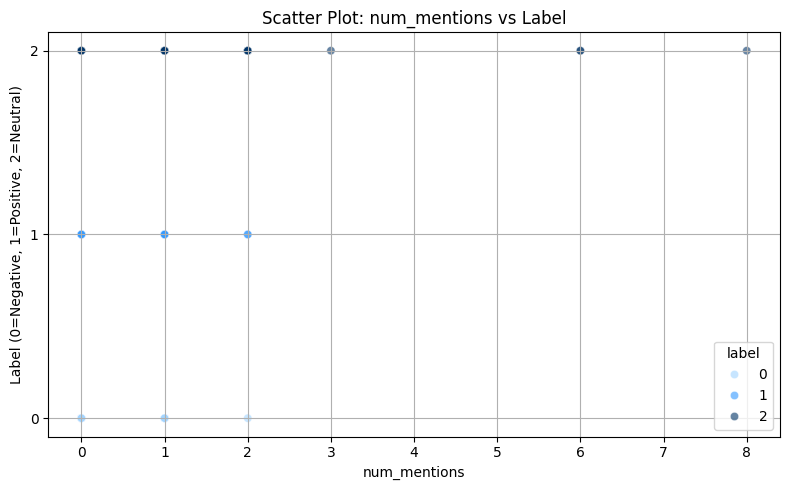

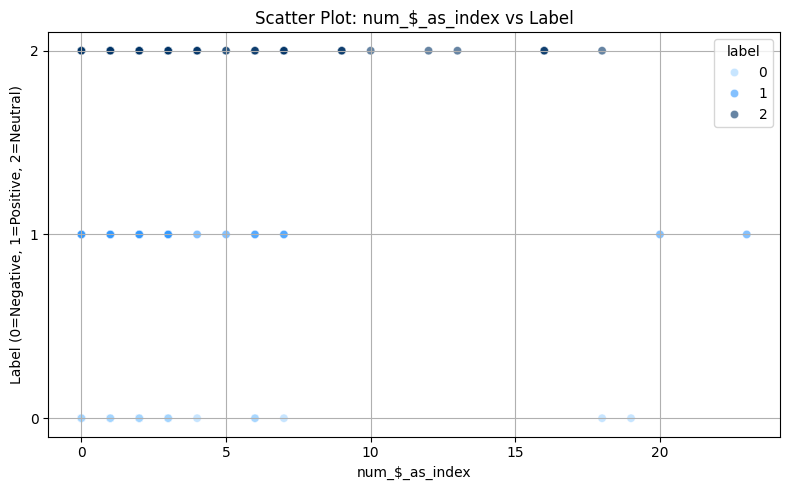

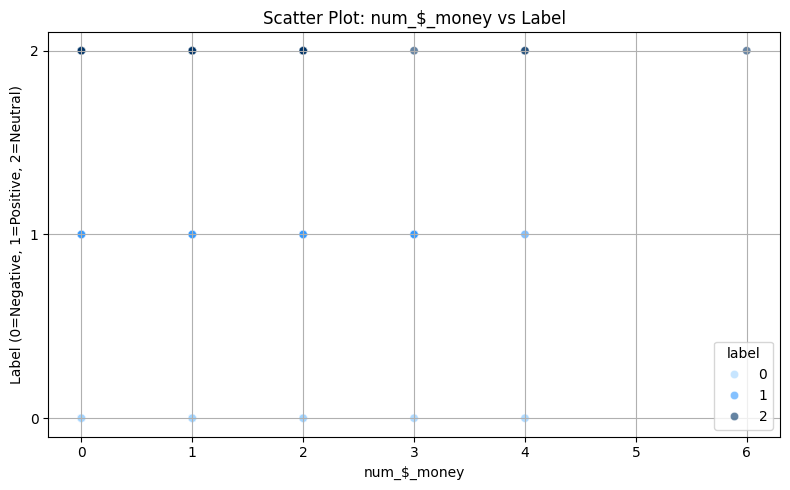

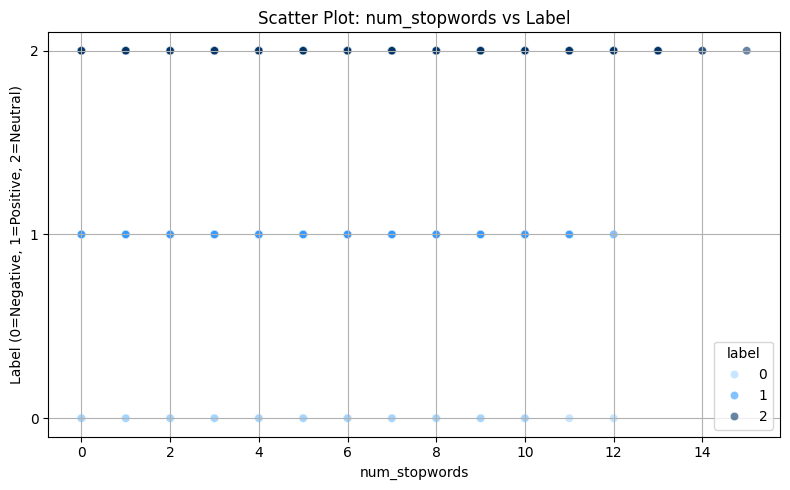

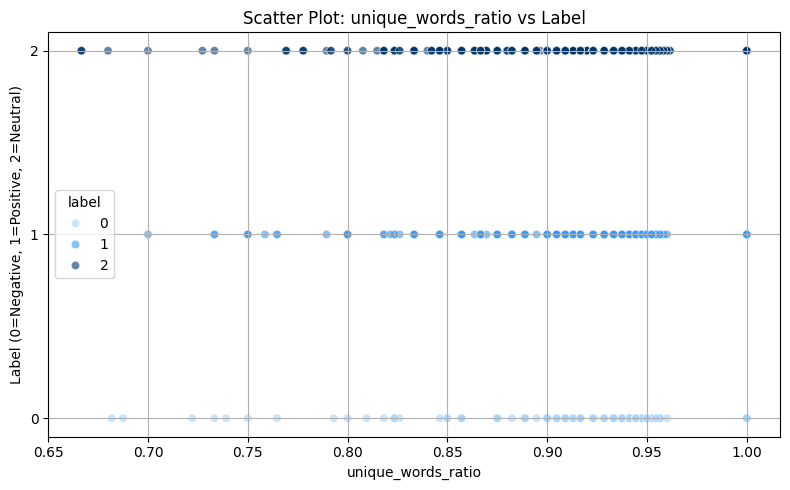

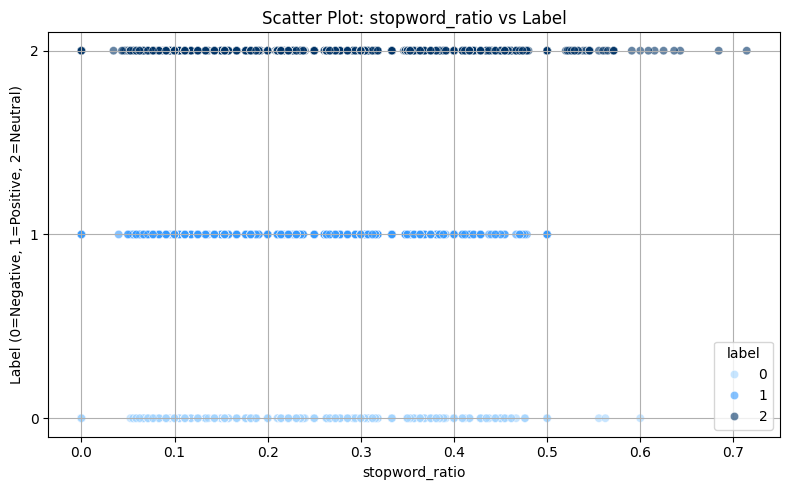

In [ ]:
for feature in features:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=train_data, x=feature, y='label', hue='label', palette=blue_palette, alpha=0.6)
    plt.title(f"Scatter Plot: {feature} vs Label")
    plt.xlabel(feature)
    plt.ylabel("Label (0=Negative, 1=Positive, 2=Neutral)")
    plt.yticks([0, 1, 2])
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### 2.5.2. Boxplot Analysis

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


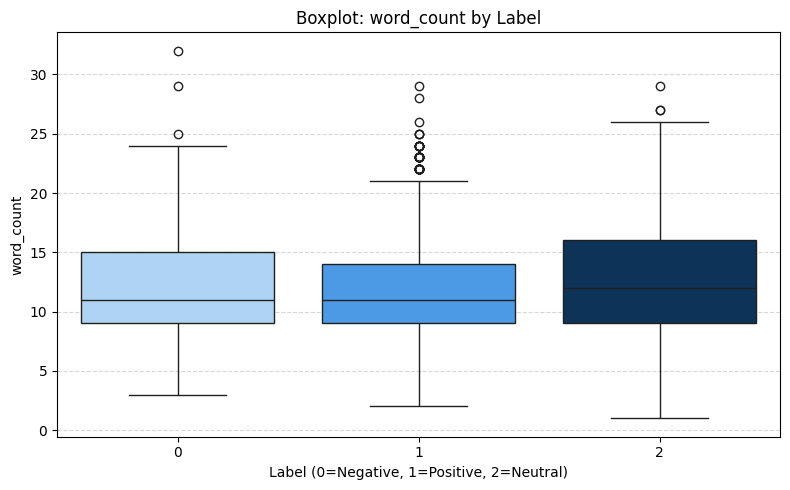

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


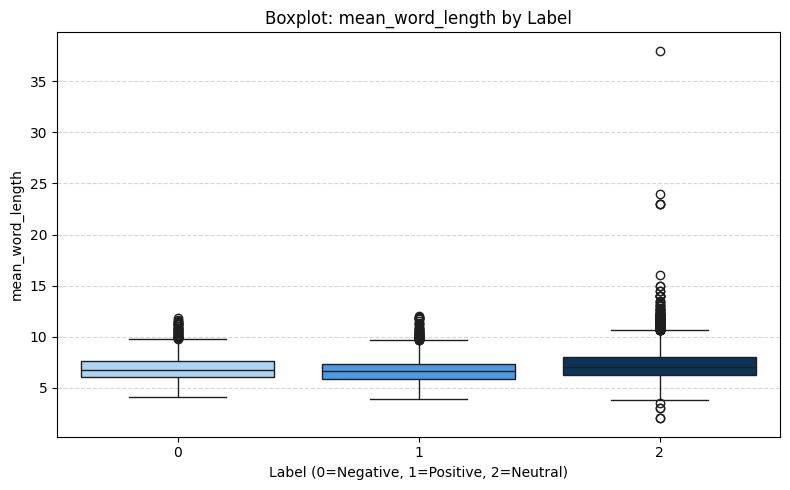

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


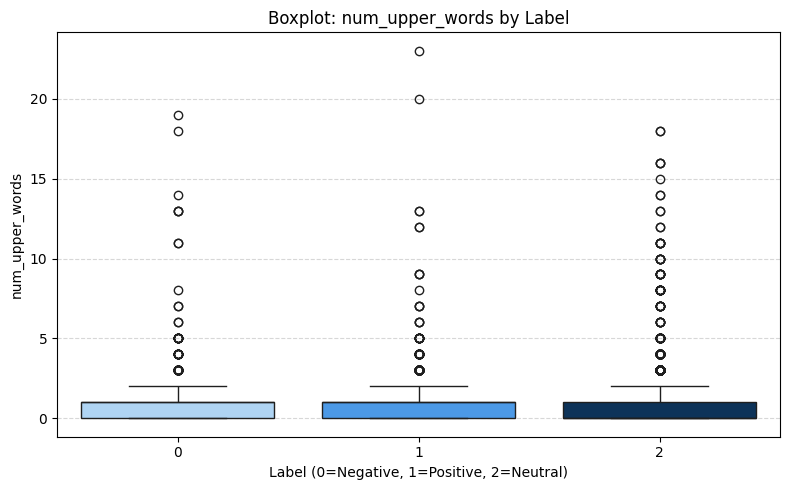

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


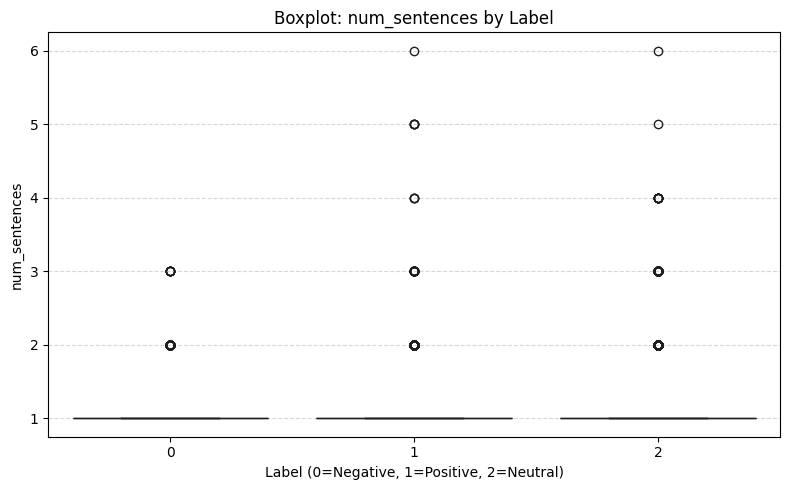

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


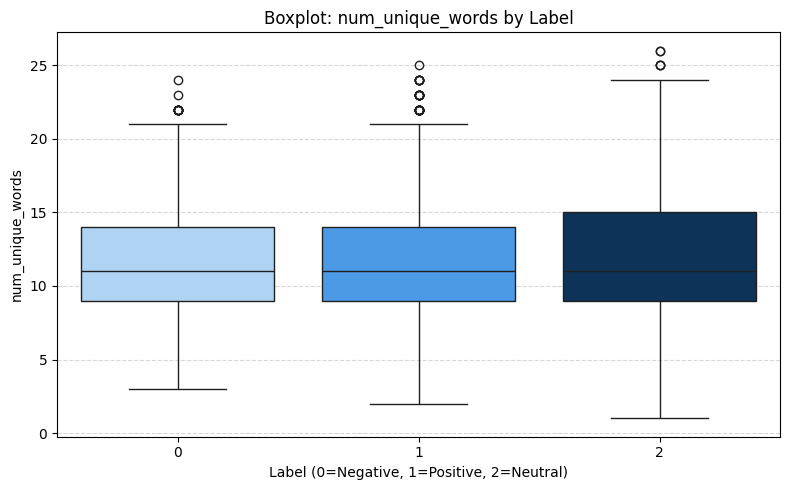

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


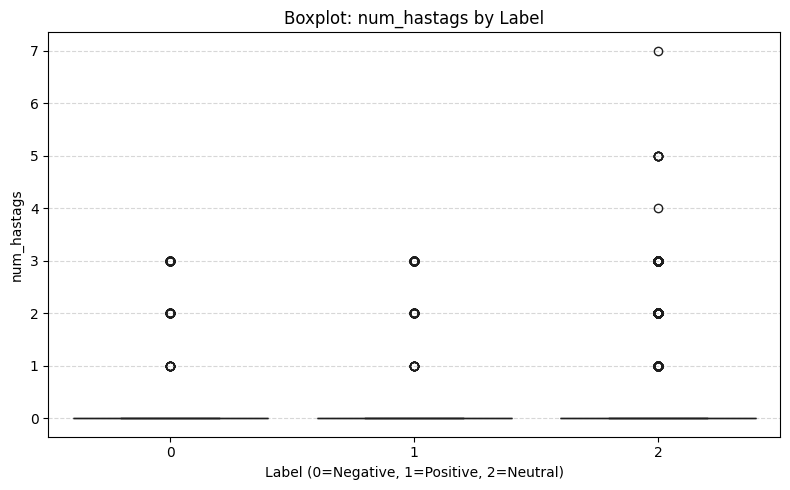

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


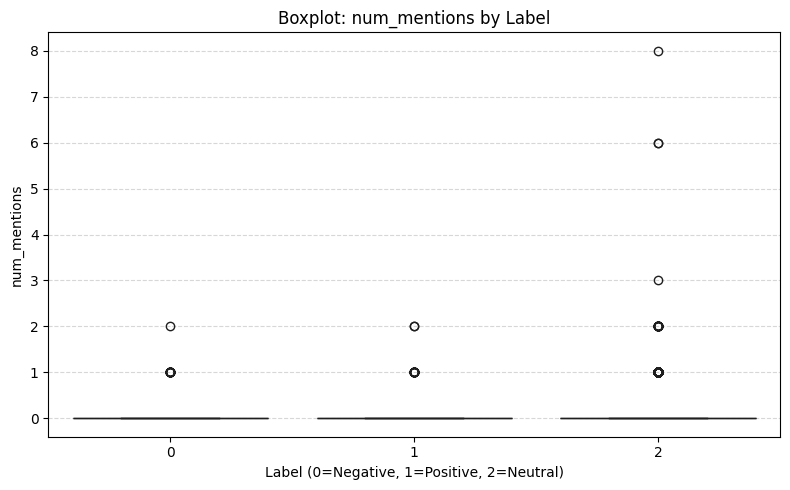

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


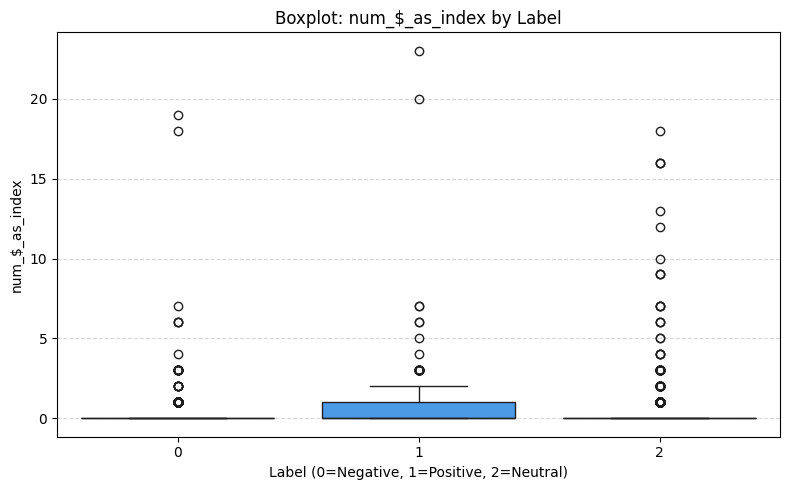

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


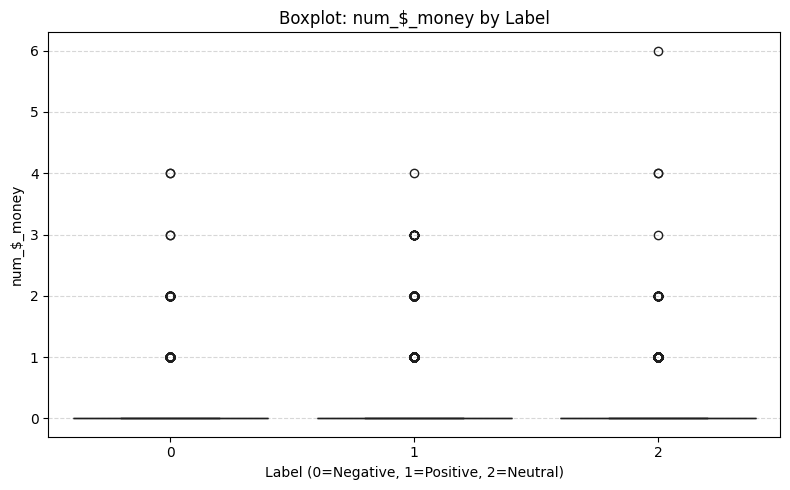

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


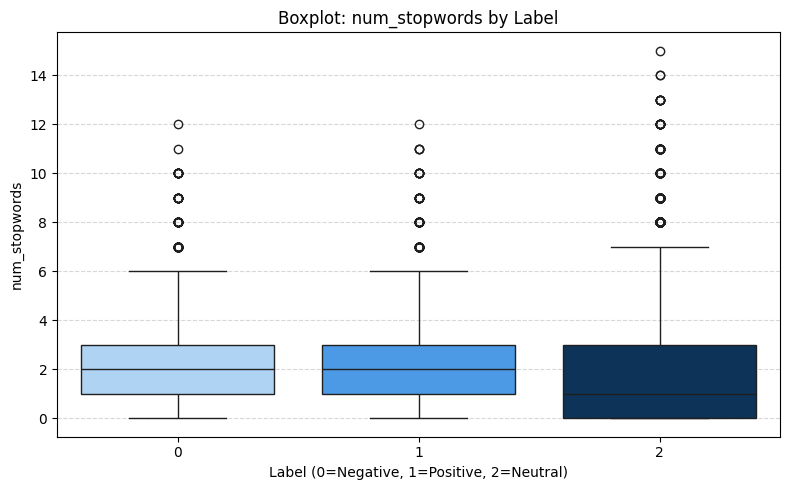

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


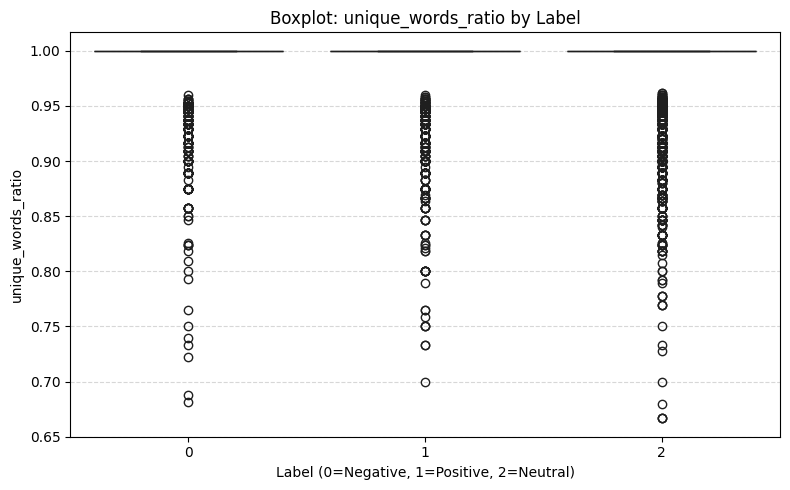

<ipython-input-141-3719624391>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)


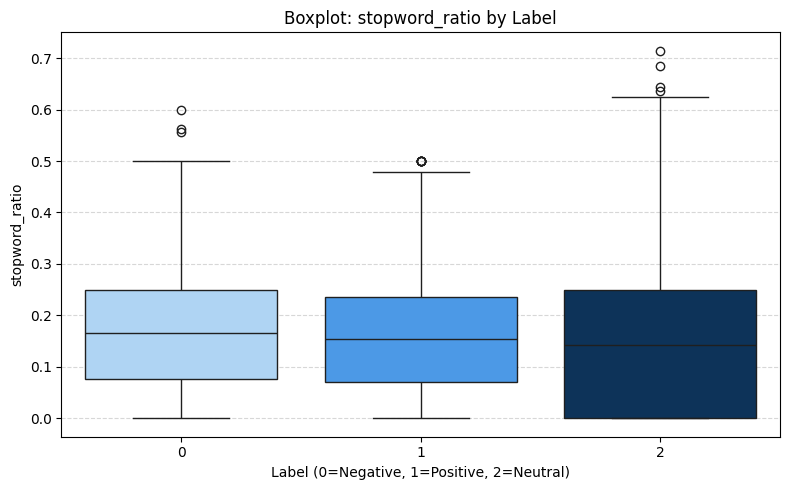

In [ ]:
# Loop through features and plot boxplots
for feature in features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=train_data, x='label', y=feature, palette=blue_palette)
    plt.title(f"Boxplot: {feature} by Label")
    plt.xlabel("Label (0=Negative, 1=Positive, 2=Neutral)")
    plt.ylabel(feature)
    plt.grid(True, axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

### 2.5.3. Correlation Matrix

<Axes: >

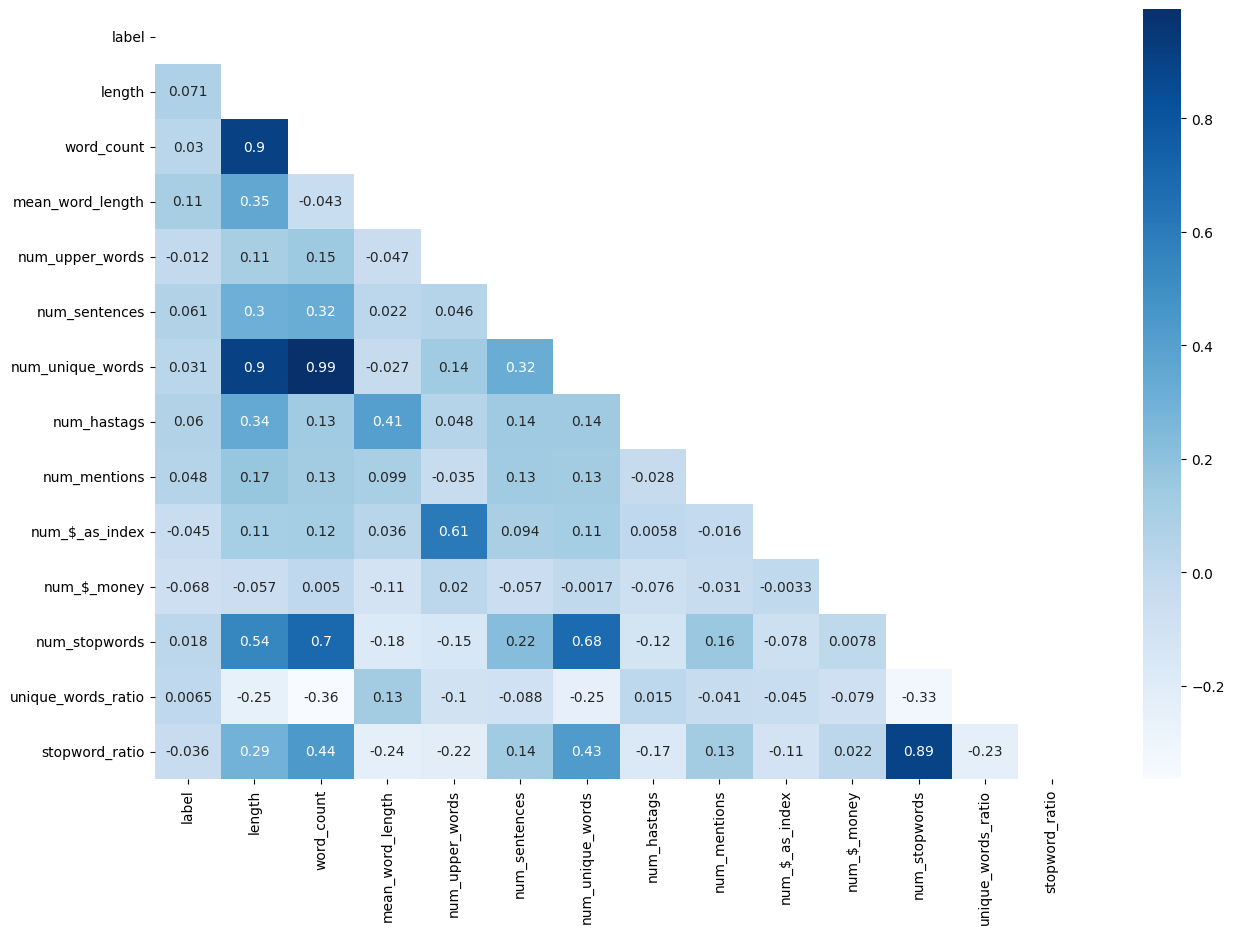

In [ ]:
corr=train_data[['label', 'length', 'word_count', 'mean_word_length',
       'num_upper_words', 'num_sentences', 'num_unique_words', 'num_hastags',
       'num_mentions', 'num_$_as_index', 'num_$_money', 'num_stopwords',
       'unique_words_ratio', 'stopword_ratio']].corr()

fig, ax = plt.subplots(figsize=(15,10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr,annot=True,mask=mask, ax=ax, cmap="Blues")




## 2.6. Word Analysis

### 2.6.1. Word Frequency

In [ ]:
all_words = ' '.join(train_data['text']).split()
freq = pd.Series(all_words).value_counts()
freq.sort_values(ascending=False)[0:10]

,count
to,2332
the,1820
of,1464
-,1390
in,1361
on,1136
for,1032
a,970
and,898
The,663


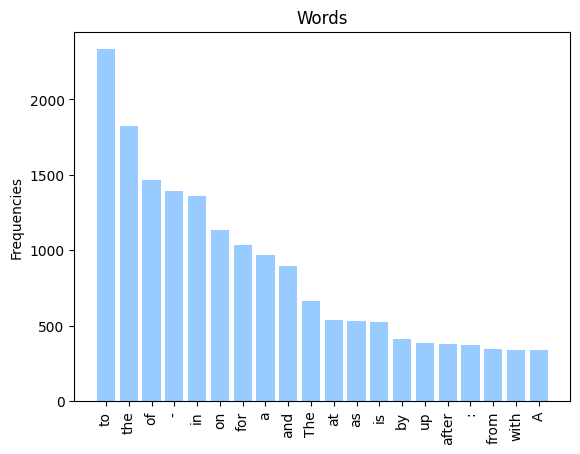

In [ ]:
x_labels = freq.index[0:20]
values = freq[:20]
plt.bar(x_labels, values, align='center', alpha=0.5, color='#3399FF')
plt.xticks(x_labels)
plt.ylabel('Frequencies')
plt.title('Words')
plt.xticks(rotation=90)
plt.show()


### 2.6.2. Raw Text Wordcloud

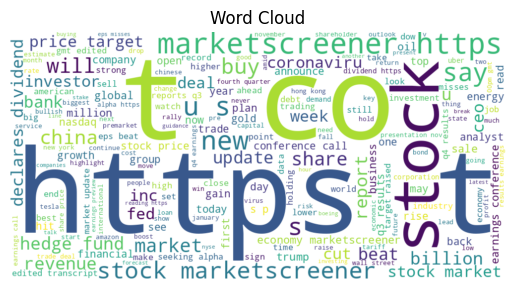

In [ ]:
raw_text = ' '.join(train_data['text'].fillna('')).lower()
raw_wc = WordCloud(width=1000, height=500, background_color='white').generate(raw_text)
plt.imshow(raw_wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud')
plt.show()

### 2.6.3. Wordcloud by Sentiment

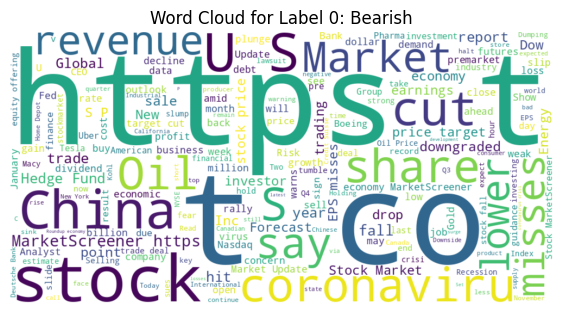

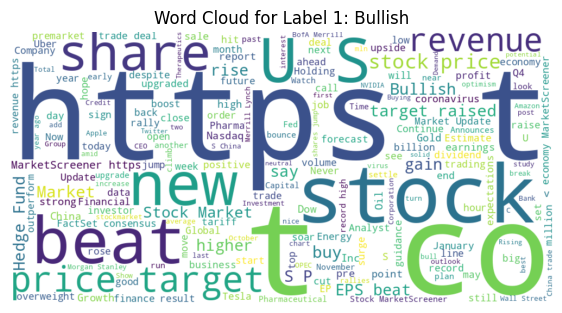

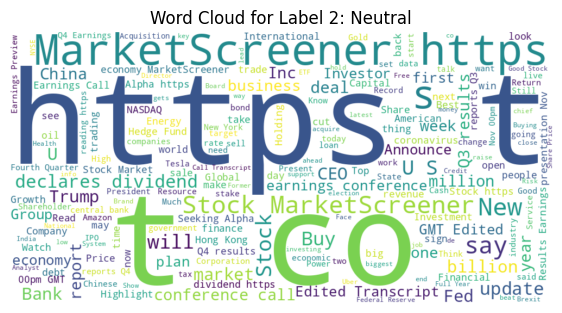

In [ ]:
label_names = {
    0: "Bearish",
    1: "Bullish",
    2: "Neutral"
}

for label in train_data['label'].unique():
    subset = train_data[train_data['label'] == label]
    text = ' '.join(subset['text'].dropna())
    wc = WordCloud(width=1000, height=500, background_color='white').generate(text)
    plt.figure(figsize=(7, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Word Cloud for Label {label}: {label_names.get(label, 'Unknown')}")
    plt.show()


#### **Label 0: Bearish**
***Dominant Words:***  
`cut`, `lower`, `coronavirus`, `oil`, `china`, `miss`, `downgraded`, `risk`

***Insights:***
- Tweets in this class focus on **negative or risk-related terms**.
- Common topics include **downgrades**, **economic/political uncertainty**, and **missed targets**.
- Suggests a **pessimistic outlook** on market or stock performance.

---

#### **Label 1: Bullish**
***Dominant Words:***  
`price`, `target`, `new`, `gain`, `raised`, `beat`, `growth`

***Insights:***
- Language is **optimistic and performance-driven**.
- Mentions of **raising price targets**, **positive earnings ("beat")**, and **market gains** are frequent.
- Reflects investor **confidence** or **expectations of growth**.

---

#### **Label 2: Neutral**
***Dominant Words:***  
`report`, `says`, `results`, `call`, `dividend`, `announces`, `presentation`

***Insights:***
- Tweets are more **factual, informative**, and **neutral in tone**.
- They cover **earnings reports**, **conference calls**, **dividends**, and other announcements.
- Show **lack of sentiment polarity**, hence classified as Neutral.
